In [52]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [53]:
# --- 1. CARGA DE DATOS ---
# Sustituye 'tu_archivo.xlsx' por el nombre real de tu excel
file_path = 'KNN_DATA.xlsx' 
df = pd.read_excel(file_path)

In [54]:
# --- 2. CONFIGURACIÓN DEL MODELO ---
# Definimos las columnas exactas que me has dicho
features = ['FAC2', 'FAC3', 'FAC4', 'FAC5']
target = 'TAMAÑO'     # 1,00 o 0,00
ticker_col = 'NOMBRE' # Donde están los tickers (AAPL, MSFT...)

X = df[features]
y = df[target]

# Dividimos 70% entrenamiento y 30% test (random_state=42 para que sea replicable siempre igual)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Creamos el modelo con k=11
k = 11
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train, y_train)

,n_neighbors,11
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [55]:

# --- 3. RESULTADOS GENERALES (Réplica de SPSS) ---
print("--- RENDIMIENTO DEL MODELO (K=11) ---")
y_pred = knn.predict(X_test)

print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nInforme de Clasificación:")
print(classification_report(y_test, y_pred))

--- RENDIMIENTO DEL MODELO (K=11) ---

Matriz de Confusión:
[[63 13]
 [32 43]]

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.66      0.83      0.74        76
           1       0.77      0.57      0.66        75

    accuracy                           0.70       151
   macro avg       0.72      0.70      0.70       151
weighted avg       0.72      0.70      0.70       151



In [56]:
import pandas as pd

# --- ANÁLISIS INTEGRAL: LAS 'BIG 7' Y SUS VECINOS (CON CONTADOR DE PARES) ---

# 1. Configuración (Asegúrate de incluir GOOG y GOOGL si tu data las tiene)
big7_tickers = ['AAPL', 'MSFT', 'GOOG', 'GOOGL', 'AMZN', 'NVDA', 'TSLA', 'META']
print(f"\n📊 GENERANDO MASTER TABLE CON MÉTRICA DE COHESIÓN...\n")

# 2. Filtramos los datos de estas empresas
big7_data = df[df[ticker_col].isin(big7_tickers)].copy()
# Opcional: Eliminar duplicados de Google si solo quieres analizar una
# big7_data = big7_data.drop_duplicates(subset=[ticker_col], keep='first')

if not big7_data.empty:
    # Variables para el modelo
    X_big7 = big7_data[features]
    
    # 3. Obtenemos predicciones y vecinos
    predicciones_big7 = knn.predict(X_big7)
    distancias, indices_vecinos = knn.kneighbors(X_big7)
    
    resultados_master = []
    
    # 4. Iteramos por cada empresa "Big 7"
    for i, (idx_original, row) in enumerate(big7_data.iterrows()):
        # --- DATOS DE LA EMPRESA ---
        nombre_empresa = row[ticker_col]
        clase_real_str = "Grande" if row[target] == 1 else "Pequeña"
        clase_pred_str = "Grande" if predicciones_big7[i] == 1 else "Pequeña"
        
        # --- ANÁLISIS DE VECINOS ---
        indices_de_este_caso = indices_vecinos[i]
        
        # Consenso (Votos de tamaño)
        vecinos_y_train = y_train.iloc[indices_de_este_caso]
        votos_positivos = (vecinos_y_train == 1).sum()
        consenso_str = f"{votos_positivos}/{k} ({(votos_positivos/k)*100:.0f}%)"
        
        # Recuperamos los datos de los vecinos
        indices_originales_vecinos = X_train.iloc[indices_de_este_caso].index
        datos_vecinos = df.loc[indices_originales_vecinos]
        distancias_este_caso = distancias[i]
        
        # --- NUEVO: CONTADOR DE OTRAS BIG 7 ---
        lista_vecinos_str = []
        count_big7_neighbors = 0 # Iniciamos contador
        
        for j, (idx_v, row_v) in enumerate(datos_vecinos.iterrows()):
            nombre_v = row_v[ticker_col]
            clase_v = "G" if row_v[target] == 1 else "P"
            dist_v = distancias_este_caso[j]
            
            # Formato texto
            item = f"{nombre_v} ({clase_v}: {dist_v:.2f})"
            lista_vecinos_str.append(item)
            
            # LÓGICA DEL CONTADOR:
            # Si el vecino está en la lista Big 7 Y NO ES ella misma
            if (nombre_v in big7_tickers) and (nombre_v != nombre_empresa):
                count_big7_neighbors += 1
            
        detalle_vecinos_final = ", ".join(lista_vecinos_str)
        
        # --- GUARDAMOS TODO ---
        resultados_master.append({
            'Ticker': nombre_empresa,
            'Real': clase_real_str,
            'Predicción': clase_pred_str,
            'Consenso': consenso_str,
            'Otras Big7 Vecinas': f"{count_big7_neighbors}", # Nueva Columna
            'Lista Detallada': detalle_vecinos_final
        })
    
    # 5. CREACIÓN DEL DATAFRAME FINAL
    df_master = pd.DataFrame(resultados_master)
    
    # Mostramos en pantalla
    print("Vista previa de la tabla:")
    print(df_master.head().to_markdown(index=False)) 
    
    # Exportar
    nombre_archivo_salida = 'Master_Table_Big7_Final.xlsx'
    df_master.to_excel(nombre_archivo_salida, index=False)
    print(f"\n✅ Tabla guardada como '{nombre_archivo_salida}'.")

else:
    print("⚠️ Error: No se encontraron los tickers de las Big 7.")


📊 GENERANDO MASTER TABLE CON MÉTRICA DE COHESIÓN...

Vista previa de la tabla:
| Ticker   | Real   | Predicción   | Consenso    |   Otras Big7 Vecinas | Lista Detallada                                                                                                                                                              |
|:---------|:-------|:-------------|:------------|---------------------:|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| GOOG     | Grande | Grande       | 8/11 (73%)  |                    3 | GOOG (G: 0.00), BKNG (G: 1.03), MSFT (G: 1.06), AAPL (G: 1.13), NVR (P: 1.39), AZO (G: 2.47), MTD (P: 2.56), AMZN (G: 2.58), HD (G: 2.80), DPZ (P: 2.80), IDXX (G: 2.90)     |
| AMZN     | Grande | Grande       | 10/11 (91%) |                    0 | AMZN (G: 0.00), COST (G: 1.44), MCK (G: 1.53), WMT (G: 1.60), AZO (G: 1.80), HCA (G: 2.01), AXP (G:

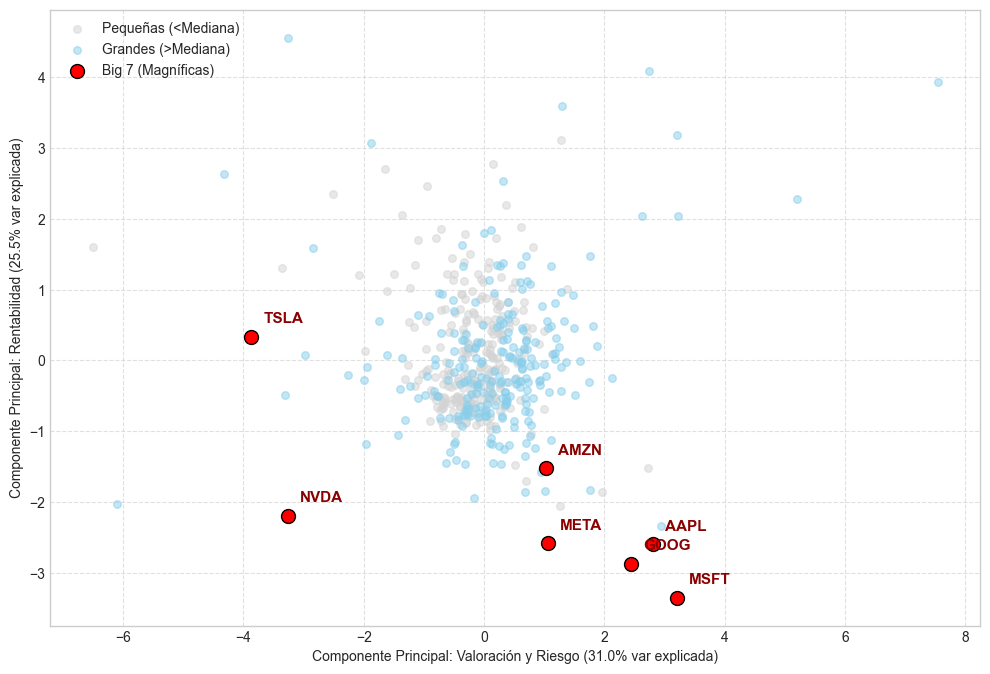

Gráfico generado y guardado como 'grafico_pca_big7.png'


In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Preparamos los datos para el gráfico
# Usamos TODAS las empresas (X) para que se vea el contexto global
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X) # Aplastamos las 4 dimensiones a 2

# Creamos un DataFrame temporal para facilitar el ploteo
df_plot = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_plot['Ticker'] = df[ticker_col].values
df_plot['Tamaño'] = y.values # 1=Grande, 0=Pequeña
df_plot['Es_Big7'] = df_plot['Ticker'].isin(big7_tickers)

# 2. Configuración del gráfico
plt.figure(figsize=(12, 8))

# Capa 1: El fondo (Resto de empresas)
# Pequeñas
subset_0 = df_plot[(df_plot['Tamaño'] == 0) & (~df_plot['Es_Big7'])]
plt.scatter(subset_0['PC1'], subset_0['PC2'], c='lightgray', label='Pequeñas (<Mediana)', alpha=0.5, s=30)

# Grandes
subset_1 = df_plot[(df_plot['Tamaño'] == 1) & (~df_plot['Es_Big7'])]
plt.scatter(subset_1['PC1'], subset_1['PC2'], c='skyblue', label='Grandes (>Mediana)', alpha=0.5, s=30)

# Capa 2: Las Big 7 (Destacadas)
subset_big7 = df_plot[df_plot['Es_Big7']]
plt.scatter(subset_big7['PC1'], subset_big7['PC2'], c='red', label='Big 7 (Magníficas)', s=100, edgecolors='black')

# 3. Ponemos las etiquetas de los nombres
for i, row in subset_big7.iterrows():
    plt.text(row['PC1']+0.2, row['PC2']+0.2, row['Ticker'], fontsize=11, fontweight='bold', color='darkred')

# Detalles finales
plt.xlabel(f'Componente Principal: Valoración y Riesgo ({pca.explained_variance_ratio_[0]:.1%} var explicada)')
plt.ylabel(f'Componente Principal: Rentabilidad ({pca.explained_variance_ratio_[1]:.1%} var explicada)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Guardar y mostrar
plt.savefig('grafico_pca_big7.png', dpi=300)
plt.show()
print("Gráfico generado y guardado como 'grafico_pca_big7.png'")

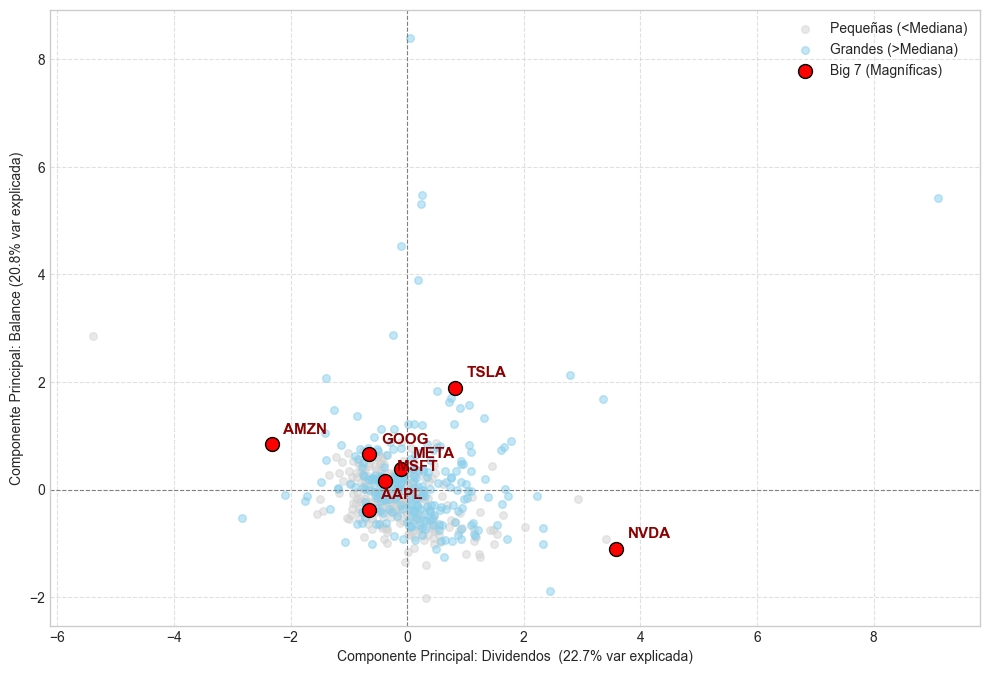

Gráfico generado: grafico_pca_big7_pc3_pc4.png


In [58]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA

# 1. Preparamos los datos (Calculamos 4 para llegar a la 3ª y 4ª)
pca = PCA(n_components=4) 
X_pca = pca.fit_transform(X)

# Creamos el DataFrame estructurado como en tu ejemplo de estilo
df_plot = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3', 'PC4'])
df_plot['Ticker'] = df[ticker_col].values
df_plot['Tamaño'] = y.values # 1=Grande, 0=Pequeña
df_plot['Es_Big7'] = df_plot['Ticker'].isin(big7_tickers)

# 2. Configuración del gráfico (Estilo "Clean")
plt.figure(figsize=(12, 8))

# Capa 1: El fondo (Resto de empresas) - ¡OJO! Aquí usamos PC3 y PC4
# Pequeñas
subset_0 = df_plot[(df_plot['Tamaño'] == 0) & (~df_plot['Es_Big7'])]
plt.scatter(subset_0['PC3'], subset_0['PC4'], c='lightgray', label='Pequeñas (<Mediana)', alpha=0.5, s=30)

# Grandes
subset_1 = df_plot[(df_plot['Tamaño'] == 1) & (~df_plot['Es_Big7'])]
plt.scatter(subset_1['PC3'], subset_1['PC4'], c='skyblue', label='Grandes (>Mediana)', alpha=0.5, s=30)

# Capa 2: Las Big 7 (Destacadas en las dimensiones ocultas)
subset_big7 = df_plot[df_plot['Es_Big7']]
plt.scatter(subset_big7['PC3'], subset_big7['PC4'], c='red', label='Big 7 (Magníficas)', s=100, edgecolors='black')

# 3. Etiquetas de nombres (Asegurando que se pintan en las coordenadas PC3, PC4)
for i, row in subset_big7.iterrows():
    plt.text(row['PC3']+0.2, row['PC4']+0.2, row['Ticker'], fontsize=11, fontweight='bold', color='darkred')

# Detalles finales y Varianza Explicada (Indices 2 y 3 corresponden a PC3 y PC4)
var_exp = pca.explained_variance_ratio_
plt.xlabel(f'Componente Principal: Dividendos  ({var_exp[2]:.1%} var explicada)')
plt.ylabel(f'Componente Principal: Balance ({var_exp[3]:.1%} var explicada)')

plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(0, color='grey', linewidth=0.8, linestyle='--') # Mantenemos los ejes centrales, ayudan a ver cuadrantes
plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')

# Guardar y mostrar
plt.savefig('grafico_pca_big7_pc3_pc4.png', dpi=300)
plt.show()
print("Gráfico generado: grafico_pca_big7_pc3_pc4.png")